In [152]:
#Importing Pandas Module
import pandas as pd

In [153]:
#Import dataset(csv file) and assigning a name
no_show_data = pd.read_csv('KaggleV2-May-2016.csv')
no_show_data.head()

,PatientId,AppointmentID,Gender,ScheduledDay,AppointmentDay,Age,Neighbourhood,Scholarship,Hipertension,Diabetes,Alcoholism,Handcap,SMS_received,No-show
0,2.987250e+13,5642903,F,2016-04-29T18:38:08Z,2016-04-29T00:00:00Z,62,JARDIM DA PENHA,0,1,0,0,0,0,No
1,5.589978e+14,5642503,M,2016-04-29T16:08:27Z,2016-04-29T00:00:00Z,56,JARDIM DA PENHA,0,0,0,0,0,0,No
2,4.262962e+12,5642549,F,2016-04-29T16:19:04Z,2016-04-29T00:00:00Z,62,MATA DA PRAIA,0,0,0,0,0,0,No
3,8.679512e+11,5642828,F,2016-04-29T17:29:31Z,2016-04-29T00:00:00Z,8,PONTAL DE CAMBURI,0,0,0,0,0,0,No
4,8.841186e+12,5642494,F,2016-04-29T16:07:23Z,2016-04-29T00:00:00Z,56,JARDIM DA PENHA,0,1,1,0,0,0,No


In [154]:
#Let's see the number of rows and columns
no_show_data.shape

(110527, 14)

There are 110,527 individuals who are stratified into 14 columns. However, not all of these rows are important.
#The dataset of interest to us includes individuals who didn't show up for a medical appointment.
#Variable of interest is the 'No-show' column.

In [155]:
#However, let's determine the proportion of people who were no-show compared to those who showed up
#Let's first determine the number of no-shows first
no_show_data[no_show_data['No-show'] == 'Yes'].shape

(22319, 14)

In [156]:
#Proportion of no-shows
no_show_data[no_show_data['No-show'] == 'Yes'].shape[0] * 100 / no_show_data.shape[0]

20.193255946510806

The proportion of patients who did not show up for their appointments is approximately 20.19%.
This is the proportion that is of interest to us.

In [157]:
#Creating a new pipeline with above variable
no_show_data_Yes = no_show_data[no_show_data['No-show'] == 'Yes']
no_show_data_Yes.head()

,PatientId,AppointmentID,Gender,ScheduledDay,AppointmentDay,Age,Neighbourhood,Scholarship,Hipertension,Diabetes,Alcoholism,Handcap,SMS_received,No-show
6,7.336882e+14,5630279,F,2016-04-27T15:05:12Z,2016-04-29T00:00:00Z,23,GOIABEIRAS,0,0,0,0,0,0,Yes
7,3.449833e+12,5630575,F,2016-04-27T15:39:58Z,2016-04-29T00:00:00Z,39,GOIABEIRAS,0,0,0,0,0,0,Yes
11,7.542951e+12,5620163,M,2016-04-26T08:44:12Z,2016-04-29T00:00:00Z,29,NOVA PALESTINA,0,0,0,0,0,1,Yes
17,1.479497e+13,5633460,F,2016-04-28T09:28:57Z,2016-04-29T00:00:00Z,40,CONQUISTA,1,0,0,0,0,0,Yes
20,6.222575e+14,5626083,F,2016-04-27T07:51:14Z,2016-04-29T00:00:00Z,30,NOVA PALESTINA,0,0,0,0,0,0,Yes


In [158]:
#Let's also create a new pipeline to work with
no_show_data1 = no_show_data.copy()

In [159]:
#looking at shape of new dataset
no_show_data1.shape

(110527, 14)

In [160]:
#Firstly, formatting of some column names is necessary to correct spelling errors and make code better readable
#Let's see the columns individually
no_show_data1.columns

Index(['PatientId', 'AppointmentID', 'Gender', 'ScheduledDay',
       'AppointmentDay', 'Age', 'Neighbourhood', 'Scholarship', 'Hipertension',
       'Diabetes', 'Alcoholism', 'Handcap', 'SMS_received', 'No-show'],
      dtype='object')

In [161]:
#Some Columns are not properly formatted hence, we'll use the rename function
no_show_data1.rename(columns={'Hipertension': 'Hypertension', 'Handcap': 'Handicap', 'SMS_received': 'SMS_Received',
                              'No-show': 'No_Show', 'PatientId': 'Patient_ID', 'AppointmentID': 'Appointment_ID',
                              'ScheduledDay': 'Scheduled_Day', 'AppointmentDay': 'Appointment_Day' }, inplace=True)


In [162]:
#Let's see if corrections were properly implemented
no_show_data1.columns

Index(['Patient_ID', 'Appointment_ID', 'Gender', 'Scheduled_Day',
       'Appointment_Day', 'Age', 'Neighbourhood', 'Scholarship',
       'Hypertension', 'Diabetes', 'Alcoholism', 'Handicap', 'SMS_Received',
       'No_Show'],
      dtype='object')

In [163]:
#Secondly, let's look at the data type of variables and if they're adequate for analysis
no_show_data1.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 110527 entries, 0 to 110526
Data columns (total 14 columns):
 #   Column           Non-Null Count   Dtype  
---  ------           --------------   -----  
 0   Patient_ID       110527 non-null  float64
 1   Appointment_ID   110527 non-null  int64  
 2   Gender           110527 non-null  object 
 3   Scheduled_Day    110527 non-null  object 
 4   Appointment_Day  110527 non-null  object 
 5   Age              110527 non-null  int64  
 6   Neighbourhood    110527 non-null  object 
 7   Scholarship      110527 non-null  int64  
 8   Hypertension     110527 non-null  int64  
 9   Diabetes         110527 non-null  int64  
 10  Alcoholism       110527 non-null  int64  
 11  Handicap         110527 non-null  int64  
 12  SMS_Received     110527 non-null  int64  
 13  No_Show          110527 non-null  object 
dtypes: float64(1), int64(8), object(5)
memory usage: 11.8+ MB


Every data type is adequate for analysis bar Scheduled_Day and Appointment_Day which are objects.
They should be converted to date-time series

In [164]:
#Converting 'Scheduled_Day' column to date-time series
no_show_data1['Scheduled_Day'] = pd.to_datetime(no_show_data1['Scheduled_Day'])

In [165]:
#Confirming conversion
no_show_data1.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 110527 entries, 0 to 110526
Data columns (total 14 columns):
 #   Column           Non-Null Count   Dtype              
---  ------           --------------   -----              
 0   Patient_ID       110527 non-null  float64            
 1   Appointment_ID   110527 non-null  int64              
 2   Gender           110527 non-null  object             
 3   Scheduled_Day    110527 non-null  datetime64[ns, UTC]
 4   Appointment_Day  110527 non-null  object             
 5   Age              110527 non-null  int64              
 6   Neighbourhood    110527 non-null  object             
 7   Scholarship      110527 non-null  int64              
 8   Hypertension     110527 non-null  int64              
 9   Diabetes         110527 non-null  int64              
 10  Alcoholism       110527 non-null  int64              
 11  Handicap         110527 non-null  int64              
 12  SMS_Received     110527 non-null  int64              
 13 

In [166]:
#Converting 'Appointment_Day' column to date-time series
no_show_data1['Appointment_Day'] = pd.to_datetime(no_show_data1['Appointment_Day'])

In [167]:
#Confirming conversion
no_show_data1.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 110527 entries, 0 to 110526
Data columns (total 14 columns):
 #   Column           Non-Null Count   Dtype              
---  ------           --------------   -----              
 0   Patient_ID       110527 non-null  float64            
 1   Appointment_ID   110527 non-null  int64              
 2   Gender           110527 non-null  object             
 3   Scheduled_Day    110527 non-null  datetime64[ns, UTC]
 4   Appointment_Day  110527 non-null  datetime64[ns, UTC]
 5   Age              110527 non-null  int64              
 6   Neighbourhood    110527 non-null  object             
 7   Scholarship      110527 non-null  int64              
 8   Hypertension     110527 non-null  int64              
 9   Diabetes         110527 non-null  int64              
 10  Alcoholism       110527 non-null  int64              
 11  Handicap         110527 non-null  int64              
 12  SMS_Received     110527 non-null  int64              
 13 

In [168]:
#Let's look at the first five rows of the dataset
no_show_data1.head()

,Patient_ID,Appointment_ID,Gender,Scheduled_Day,Appointment_Day,Age,Neighbourhood,Scholarship,Hypertension,Diabetes,Alcoholism,Handicap,SMS_Received,No_Show
0,2.987250e+13,5642903,F,2016-04-29 18:38:08+00:00,2016-04-29 00:00:00+00:00,62,JARDIM DA PENHA,0,1,0,0,0,0,No
1,5.589978e+14,5642503,M,2016-04-29 16:08:27+00:00,2016-04-29 00:00:00+00:00,56,JARDIM DA PENHA,0,0,0,0,0,0,No
2,4.262962e+12,5642549,F,2016-04-29 16:19:04+00:00,2016-04-29 00:00:00+00:00,62,MATA DA PRAIA,0,0,0,0,0,0,No
3,8.679512e+11,5642828,F,2016-04-29 17:29:31+00:00,2016-04-29 00:00:00+00:00,8,PONTAL DE CAMBURI,0,0,0,0,0,0,No
4,8.841186e+12,5642494,F,2016-04-29 16:07:23+00:00,2016-04-29 00:00:00+00:00,56,JARDIM DA PENHA,0,1,1,0,0,0,No


In [169]:
#creating a new pipeline
no_show_data2 = no_show_data1.copy()

In [170]:
#Let's search for missing data in the dataset
no_show_data2.isnull().sum()

Patient_ID         0
Appointment_ID     0
Gender             0
Scheduled_Day      0
Appointment_Day    0
Age                0
Neighbourhood      0
Scholarship        0
Hypertension       0
Diabetes           0
Alcoholism         0
Handicap           0
SMS_Received       0
No_Show            0
dtype: int64

There is no missing data However, there is possibility missing data were replaced with arbitrary values. We'll look at unique values in some variables of interest Keep in mind, healthcare datasets which are real-life are very sensitive and barely contain missing data. It is also important to note that values in the 'Scholarship', 'Hypertension', 'Diabetes', 'Alcoholism', 'Handicap' and 'SMS_Received' columns are categorical and expected to be binary i.e. 0/1 which means No/Yes respectively.

In [171]:
#Unique values for 'Gender'
no_show_data2['Gender'].unique()

array(['F', 'M'], dtype=object)

There are no arbitrary values here

In [172]:
#Unique values for 'Age'
no_show_data2['Age'].unique()

array([ 62,  56,   8,  76,  23,  39,  21,  19,  30,  29,  22,  28,  54,
        15,  50,  40,  46,   4,  13,  65,  45,  51,  32,  12,  61,  38,
        79,  18,  63,  64,  85,  59,  55,  71,  49,  78,  31,  58,  27,
         6,   2,  11,   7,   0,   3,   1,  69,  68,  60,  67,  36,  10,
        35,  20,  26,  34,  33,  16,  42,   5,  47,  17,  41,  44,  37,
        24,  66,  77,  81,  70,  53,  75,  73,  52,  74,  43,  89,  57,
        14,   9,  48,  83,  72,  25,  80,  87,  88,  84,  82,  90,  94,
        86,  91,  98,  92,  96,  93,  95,  97, 102, 115, 100,  99,  -1])

From the above, there is an arbitrary value(-1) as well as extreme values - 0 and 115 which may not be arbitrary. 
-1 is practically impossible. So we remove row(s) containing this value  
0 in the age variable may indicate a child less than 1 year of age. 115 on the other is extremely rare but is not imposible.

In [173]:
#Filtering row(s) that contain -1
no_show_data2[no_show_data2['Age'] == -1]

,Patient_ID,Appointment_ID,Gender,Scheduled_Day,Appointment_Day,Age,Neighbourhood,Scholarship,Hypertension,Diabetes,Alcoholism,Handicap,SMS_Received,No_Show
99832,4.659432e+14,5775010,F,2016-06-06 08:58:13+00:00,2016-06-06 00:00:00+00:00,-1,ROMÃO,0,0,0,0,0,0,No


In [174]:
#Removing row from dataset and creating new pipeline
no_show_data3 = no_show_data2[~(no_show_data2['Age'] == -1)]
no_show_data3.head()

,Patient_ID,Appointment_ID,Gender,Scheduled_Day,Appointment_Day,Age,Neighbourhood,Scholarship,Hypertension,Diabetes,Alcoholism,Handicap,SMS_Received,No_Show
0,2.987250e+13,5642903,F,2016-04-29 18:38:08+00:00,2016-04-29 00:00:00+00:00,62,JARDIM DA PENHA,0,1,0,0,0,0,No
1,5.589978e+14,5642503,M,2016-04-29 16:08:27+00:00,2016-04-29 00:00:00+00:00,56,JARDIM DA PENHA,0,0,0,0,0,0,No
2,4.262962e+12,5642549,F,2016-04-29 16:19:04+00:00,2016-04-29 00:00:00+00:00,62,MATA DA PRAIA,0,0,0,0,0,0,No
3,8.679512e+11,5642828,F,2016-04-29 17:29:31+00:00,2016-04-29 00:00:00+00:00,8,PONTAL DE CAMBURI,0,0,0,0,0,0,No
4,8.841186e+12,5642494,F,2016-04-29 16:07:23+00:00,2016-04-29 00:00:00+00:00,56,JARDIM DA PENHA,0,1,1,0,0,0,No


In [175]:
#Confirming the shape of dataset
no_show_data3.shape

(110526, 14)

In [176]:
#Unique values for 'Neighbourhood'
no_show_data3['Neighbourhood'].unique()

array(['JARDIM DA PENHA', 'MATA DA PRAIA', 'PONTAL DE CAMBURI',
       'REPÚBLICA', 'GOIABEIRAS', 'ANDORINHAS', 'CONQUISTA',
       'NOVA PALESTINA', 'DA PENHA', 'TABUAZEIRO', 'BENTO FERREIRA',
       'SÃO PEDRO', 'SANTA MARTHA', 'SÃO CRISTÓVÃO', 'MARUÍPE',
       'GRANDE VITÓRIA', 'SÃO BENEDITO', 'ILHA DAS CAIEIRAS',
       'SANTO ANDRÉ', 'SOLON BORGES', 'BONFIM', 'JARDIM CAMBURI',
       'MARIA ORTIZ', 'JABOUR', 'ANTÔNIO HONÓRIO', 'RESISTÊNCIA',
       'ILHA DE SANTA MARIA', 'JUCUTUQUARA', 'MONTE BELO',
       'MÁRIO CYPRESTE', 'SANTO ANTÔNIO', 'BELA VISTA', 'PRAIA DO SUÁ',
       'SANTA HELENA', 'ITARARÉ', 'INHANGUETÁ', 'UNIVERSITÁRIO',
       'SÃO JOSÉ', 'REDENÇÃO', 'SANTA CLARA', 'CENTRO', 'PARQUE MOSCOSO',
       'DO MOSCOSO', 'SANTOS DUMONT', 'CARATOÍRA', 'ARIOVALDO FAVALESSA',
       'ILHA DO FRADE', 'GURIGICA', 'JOANA D´ARC', 'CONSOLAÇÃO',
       'PRAIA DO CANTO', 'BOA VISTA', 'MORADA DE CAMBURI', 'SANTA LUÍZA',
       'SANTA LÚCIA', 'BARRO VERMELHO', 'ESTRELINHA', 'FORTE SÃO 

There are no arbitrary values here

In [177]:
#Unique values for'Scholarship'
no_show_data3['Scholarship'].unique()

array([0, 1])

There are no arbitrary values here as well.

In [178]:
#Unique values for 'Hypertension'
no_show_data3['Hypertension'].unique()

array([1, 0])

No arbitrary values

In [179]:
#Unique values for 'Diabetes'
no_show_data3['Diabetes'].unique()

array([0, 1])

No arbirary values

In [180]:
#Unique values for 'Alcoholism'
no_show_data3['Alcoholism'].unique()

array([0, 1])

No arbirary values

In [182]:
#Unique values for 'Handicap'
no_show_data3['Handicap'].unique()

array([0, 1, 2, 3, 4])

Remember earlier where it was stated that values in some columns were expected to be binary. In this column, there are 5 values ranging from 0 - 4.
*Intuition*: there is a possibility values in this column may indicate severity of handicap even though there are commonly 3 forms of severity - mild, moderate and severe.
In this column, we will base value on severity of handicap on a scale of 0 - 4 with 0 meaning absence of handicap and 4 meaning the most severe form of handicap.
In that case, there are no arbitrary values.

In [183]:
#Unique values for 'SMS_Received'
no_show_data3['SMS_Received'].unique()

array([0, 1])

No arbitrary values in the above

From the dataset, there is no single missing value but there was an arbitrary value which may have been imputed earlier.
This just emphasizes the sensitivity of real-world health datasets and absence of room for missing data. Healthcare data should be as accurate as possible and valid.
**WHAT IF THERE WERE MISSING DATA?**
Reasons for missingness will be probed into. And the way missing data will be handled is dependent on if data is missing completely at random, missing at random and missing not at random.
* In the 'Patient_ID' Column: column may be dropped if there is an overwhelming amount of missing data. If missing data is < 5% of the dataset, rows may be deleted.
* In the 'Appointment_ID' Column: since data is serial, the use of linear interpolation will be used.
* In the 'Age' Column: data is numerical. Due to sensitivity of datasset and given the fact that variable is valuable for analysis, the use of arbitrary values may be used until data is properly recollected.
* In the 'Gender Column': even though variable is categorical, above illustration applies.
* In the 'Scheduled_Day' Column: since there is no specific pattern or trend, missing data may be deleted especially if missing data < 5%.
* In the 'Appointment_Day' Column: above illustration applies.
* In the 'Neighbourhood' Column: due to sensitivity of data, arbitrary values may be employed. If missing data is < 5% of the dataset, rows may be deleted. However, the use of mode can be used as well.
* In the 'Scholarship', 'Hypertension',	'Diabetes',	'Alcoholism', 'Handicap', 'SMS_Received' and 'No_Show' Columns: These variables are very important and missing values can't be merely imputed by statistical methods. Use of arbitrary values may be used until accurate data is collected  or rows deleted if missing data < 5%.

We'll remove duplicates in the data set next

In [185]:
#Identifying duplicates
no_show_data3[no_show_data3.duplicated()]

,Patient_ID,Appointment_ID,Gender,Scheduled_Day,Appointment_Day,Age,Neighbourhood,Scholarship,Hypertension,Diabetes,Alcoholism,Handicap,SMS_Received,No_Show


There are no duplicates in dataset

Next thing we'll deal with is outlier detection using statistical methods. Some methods may include the Tukey's method(or Interquartile range method'), visualization methods with the use of box plots, scatter plots, etc, probabilistic methods using the gaussian distribution.
It is very important to note that outliers are not just extreme values but unusual values. Also, not all outliers are meant to be deleted or removed. Some outliers are very necessary for data analysis.
Below is outlier detection for variables of interest

In [186]:
#Let's look at our columns again
no_show_data3.columns

Index(['Patient_ID', 'Appointment_ID', 'Gender', 'Scheduled_Day',
       'Appointment_Day', 'Age', 'Neighbourhood', 'Scholarship',
       'Hypertension', 'Diabetes', 'Alcoholism', 'Handicap', 'SMS_Received',
       'No_Show'],
      dtype='object')

In [187]:
#Let's also import some statistical modules to aid visualization
import matplotlib.pyplot as plt
import seaborn as sns

<function matplotlib.pyplot.show(close=None, block=None)>

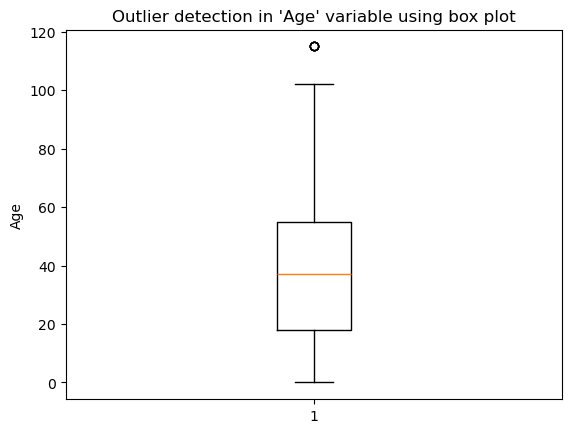

In [188]:
#Outlier detection in 'Age' variable using box and whisker plot
plt.boxplot(no_show_data3['Age'])
plt.title("Outlier detection in 'Age' variable using box plot")
plt.ylabel("Age")
plt.show

From the visual above, the lower extreme age lies around the 0 mark while the upper extereme age lies just above the 100 mark. Lower quartile(25th percentile) lies just below the 20 mark while the upper quartile(75th percentile) lies around the 60 mark. The median age(50th percentile) is around 40 years.
There is presence of an outlier close to the 120 age mark.
Let's make use of another visualization tool in detecting outlier

<function matplotlib.pyplot.show(close=None, block=None)>

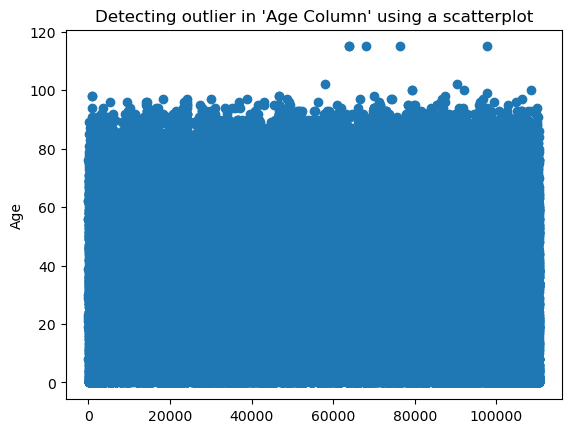

In [190]:
#Detecting outlier in 'Age Column' using a scatterplot
plt.scatter(x=no_show_data3.index, y=no_show_data3['Age'])
plt.title("Detecting outlier in 'Age Column' using a scatterplot")
plt.ylabel("Age")
plt.show

From the visualization, majority of data is clustered together. However, there are about 4 discrete values further from the cluster just around the 120 year mark. Those are the outliers

Apart from outliers in variable, there may be possible outliers in lead time i.e. time between scheduled date and appointment date. Before we go in depth, let's create a feature called 'Lead_Time' from the 'Scheduled_Day' and 'Appointment_Day' column.

In [191]:
#Create a new pipeline
no_show_data4 = no_show_data3.copy()

In [192]:
no_show_data4.head()

,Patient_ID,Appointment_ID,Gender,Scheduled_Day,Appointment_Day,Age,Neighbourhood,Scholarship,Hypertension,Diabetes,Alcoholism,Handicap,SMS_Received,No_Show
0,2.987250e+13,5642903,F,2016-04-29 18:38:08+00:00,2016-04-29 00:00:00+00:00,62,JARDIM DA PENHA,0,1,0,0,0,0,No
1,5.589978e+14,5642503,M,2016-04-29 16:08:27+00:00,2016-04-29 00:00:00+00:00,56,JARDIM DA PENHA,0,0,0,0,0,0,No
2,4.262962e+12,5642549,F,2016-04-29 16:19:04+00:00,2016-04-29 00:00:00+00:00,62,MATA DA PRAIA,0,0,0,0,0,0,No
3,8.679512e+11,5642828,F,2016-04-29 17:29:31+00:00,2016-04-29 00:00:00+00:00,8,PONTAL DE CAMBURI,0,0,0,0,0,0,No
4,8.841186e+12,5642494,F,2016-04-29 16:07:23+00:00,2016-04-29 00:00:00+00:00,56,JARDIM DA PENHA,0,1,1,0,0,0,No


In [193]:
#Creating a new column called 'Lead_Time' from the 'Scheduled_Day' and 'Appointment_Day'
no_show_data4['Lead_Time'] = no_show_data4['Appointment_Day'] - no_show_data4['Scheduled_Day']

In [194]:
no_show_data4.head(5)

,Patient_ID,Appointment_ID,Gender,Scheduled_Day,Appointment_Day,Age,Neighbourhood,Scholarship,Hypertension,Diabetes,Alcoholism,Handicap,SMS_Received,No_Show,Lead_Time
0,2.987250e+13,5642903,F,2016-04-29 18:38:08+00:00,2016-04-29 00:00:00+00:00,62,JARDIM DA PENHA,0,1,0,0,0,0,No,-1 days +05:21:52
1,5.589978e+14,5642503,M,2016-04-29 16:08:27+00:00,2016-04-29 00:00:00+00:00,56,JARDIM DA PENHA,0,0,0,0,0,0,No,-1 days +07:51:33
2,4.262962e+12,5642549,F,2016-04-29 16:19:04+00:00,2016-04-29 00:00:00+00:00,62,MATA DA PRAIA,0,0,0,0,0,0,No,-1 days +07:40:56
3,8.679512e+11,5642828,F,2016-04-29 17:29:31+00:00,2016-04-29 00:00:00+00:00,8,PONTAL DE CAMBURI,0,0,0,0,0,0,No,-1 days +06:30:29
4,8.841186e+12,5642494,F,2016-04-29 16:07:23+00:00,2016-04-29 00:00:00+00:00,56,JARDIM DA PENHA,0,1,1,0,0,0,No,-1 days +07:52:37


It is practically impossible for 'Scheduled_Day' to come after 'Appointment_Day'. This prompted the creation of a new column - 'Lead-Time'. If any value in this column is negative, that is an outlier.
For that, we will subset existing dataset

In [195]:
#Detecting outliers in the 'Lead-Time' column
no_show_data4[no_show_data4['Lead_Time'] < '0 days']

,Patient_ID,Appointment_ID,Gender,Scheduled_Day,Appointment_Day,Age,Neighbourhood,Scholarship,Hypertension,Diabetes,Alcoholism,Handicap,SMS_Received,No_Show,Lead_Time
0,2.987250e+13,5642903,F,2016-04-29 18:38:08+00:00,2016-04-29 00:00:00+00:00,62,JARDIM DA PENHA,0,1,0,0,0,0,No,-1 days +05:21:52
1,5.589978e+14,5642503,M,2016-04-29 16:08:27+00:00,2016-04-29 00:00:00+00:00,56,JARDIM DA PENHA,0,0,0,0,0,0,No,-1 days +07:51:33
2,4.262962e+12,5642549,F,2016-04-29 16:19:04+00:00,2016-04-29 00:00:00+00:00,62,MATA DA PRAIA,0,0,0,0,0,0,No,-1 days +07:40:56
3,8.679512e+11,5642828,F,2016-04-29 17:29:31+00:00,2016-04-29 00:00:00+00:00,8,PONTAL DE CAMBURI,0,0,0,0,0,0,No,-1 days +06:30:29
4,8.841186e+12,5642494,F,2016-04-29 16:07:23+00:00,2016-04-29 00:00:00+00:00,56,JARDIM DA PENHA,0,1,1,0,0,0,No,-1 days +07:52:37
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
110511,8.235996e+11,5786742,F,2016-06-08 08:50:20+00:00,2016-06-08 00:00:00+00:00,14,MARIA ORTIZ,0,0,0,0,0,0,No,-1 days +15:09:40
110512,9.876246e+13,5786368,F,2016-06-08 08:20:01+00:00,2016-06-08 00:00:00+00:00,41,MARIA ORTIZ,0,0,0,0,0,0,No,-1 days +15:39:59
110513,8.674778e+13,5785964,M,2016-06-08 07:52:55+00:00,2016-06-08 00:00:00+00:00,2,ANTÔNIO HONÓRIO,0,0,0,0,0,0,No,-1 days +16:07:05
110514,2.695685e+12,5786567,F,2016-06-08 08:35:31+00:00,2016-06-08 00:00:00+00:00,58,MARIA ORTIZ,0,0,0,0,0,0,No,-1 days +15:24:29


Above are possible outliers in the 'Lead-Time' column. However, there is possibility patient(s) can see the doctor on the booking date. And since the time in the 'Appointment_Day' series is formatted to 00:00:00, there is possibility our lead time may be negative.
We will circumvent this constraint by reducing lead time to minus 1(-1) day.

In [196]:
#Detecting outliers in the 'Lead-Time' column
no_show_data4[(no_show_data4['Lead_Time'] < '-1 days')]

,Patient_ID,Appointment_ID,Gender,Scheduled_Day,Appointment_Day,Age,Neighbourhood,Scholarship,Hypertension,Diabetes,Alcoholism,Handicap,SMS_Received,No_Show,Lead_Time
27033,7.839273e+12,5679978,M,2016-05-10 10:51:53+00:00,2016-05-09 00:00:00+00:00,38,RESISTÊNCIA,0,0,0,0,1,0,Yes,-2 days +13:08:07
55226,7.896294e+12,5715660,F,2016-05-18 14:50:41+00:00,2016-05-17 00:00:00+00:00,19,SANTO ANTÔNIO,0,0,0,0,1,0,Yes,-2 days +09:09:19
64175,2.425226e+13,5664962,F,2016-05-05 13:43:58+00:00,2016-05-04 00:00:00+00:00,22,CONSOLAÇÃO,0,0,0,0,0,0,Yes,-2 days +10:16:02
71533,9.982316e+14,5686628,F,2016-05-11 13:49:20+00:00,2016-05-05 00:00:00+00:00,81,SANTO ANTÔNIO,0,0,0,0,0,0,Yes,-7 days +10:10:40
72362,3.787482e+12,5655637,M,2016-05-04 06:50:57+00:00,2016-05-03 00:00:00+00:00,7,TABUAZEIRO,0,0,0,0,0,0,Yes,-2 days +17:09:03


Above are the definitive outliers obtained from the 'Lead_Time' Columns. We'll be creating a new pipeline without these outliers.

In [197]:
#Creating new pipeline excluding outliers
no_show_data5 = no_show_data4[~(no_show_data4['Lead_Time'] < '-1 days')]
no_show_data5.head()

,Patient_ID,Appointment_ID,Gender,Scheduled_Day,Appointment_Day,Age,Neighbourhood,Scholarship,Hypertension,Diabetes,Alcoholism,Handicap,SMS_Received,No_Show,Lead_Time
0,2.987250e+13,5642903,F,2016-04-29 18:38:08+00:00,2016-04-29 00:00:00+00:00,62,JARDIM DA PENHA,0,1,0,0,0,0,No,-1 days +05:21:52
1,5.589978e+14,5642503,M,2016-04-29 16:08:27+00:00,2016-04-29 00:00:00+00:00,56,JARDIM DA PENHA,0,0,0,0,0,0,No,-1 days +07:51:33
2,4.262962e+12,5642549,F,2016-04-29 16:19:04+00:00,2016-04-29 00:00:00+00:00,62,MATA DA PRAIA,0,0,0,0,0,0,No,-1 days +07:40:56
3,8.679512e+11,5642828,F,2016-04-29 17:29:31+00:00,2016-04-29 00:00:00+00:00,8,PONTAL DE CAMBURI,0,0,0,0,0,0,No,-1 days +06:30:29
4,8.841186e+12,5642494,F,2016-04-29 16:07:23+00:00,2016-04-29 00:00:00+00:00,56,JARDIM DA PENHA,0,1,1,0,0,0,No,-1 days +07:52:37


In [198]:
#Checking for shape of new dataset
no_show_data5.shape

(110521, 15)

We can handle outlier in the 'Age' column by using interquartile range method.
We will also make use of the Numpy module for Statistical methods

In [199]:
#Importing numpy module
import numpy as np

In [200]:
#Using Interquartile range/Tukey's method to handle outliers in 'Age'
#Firstly, we determine the 75th and 25th quartile using numpy
Q1 = np.percentile(no_show_data5['Age'], 25)
Q3 = np.percentile(no_show_data5['Age'], 75)

In [201]:
Q1

np.float64(18.0)

In [202]:
Q3

np.float64(55.0)

In [203]:
#Calculate the IQR using the Q3-Q1
IQR = Q3 - Q1

In [204]:
IQR

np.float64(37.0)

In [205]:
#Before applying Tukey's method, let's look at the shape of existing data set
no_show_data5.shape

(110521, 15)

In [206]:
#Using Tukey's method, let's create upper and lower limits for whuch our data should lie within
upper_limit= Q3 + 1.5 * IQR
lower_limit= Q1 - 1.5 * IQR

In [207]:
upper_limit

np.float64(110.5)

In [208]:
lower_limit

np.float64(-37.5)

Because our lower_limit cannot be negative, we'll make use of 0 as our lower limit

In [209]:
#Outliers in the 'Age' column will be
no_show_data5[(no_show_data5['Age'] > upper_limit) | (no_show_data5['Age'] < 0)]

,Patient_ID,Appointment_ID,Gender,Scheduled_Day,Appointment_Day,Age,Neighbourhood,Scholarship,Hypertension,Diabetes,Alcoholism,Handicap,SMS_Received,No_Show,Lead_Time
63912,3.196321e+13,5700278,F,2016-05-16 09:17:44+00:00,2016-05-19 00:00:00+00:00,115,ANDORINHAS,0,0,0,0,1,0,Yes,2 days 14:42:16
63915,3.196321e+13,5700279,F,2016-05-16 09:17:44+00:00,2016-05-19 00:00:00+00:00,115,ANDORINHAS,0,0,0,0,1,0,Yes,2 days 14:42:16
68127,3.196321e+13,5562812,F,2016-04-08 14:29:17+00:00,2016-05-16 00:00:00+00:00,115,ANDORINHAS,0,0,0,0,1,0,Yes,37 days 09:30:43
76284,3.196321e+13,5744037,F,2016-05-30 09:44:51+00:00,2016-05-30 00:00:00+00:00,115,ANDORINHAS,0,0,0,0,1,0,No,-1 days +14:15:09
97666,7.482346e+14,5717451,F,2016-05-19 07:57:56+00:00,2016-06-03 00:00:00+00:00,115,SÃO JOSÉ,0,1,0,0,0,1,No,14 days 16:02:04


Remember we did detect for duplicates earlier and there were none. However, the first 4 outliers above are uncannily similar. 
Since almost all variables including the 'Patient_ID' are similar for the first 4, it can be assumed that this is the same person who erroneously booked for an appointment more than once at a particular point in time and also booked seperately at different points in time. 
The last outlier may be a seperate individual.
A new pipeline without above outliers will be created just to emphasize handling of outliers using Tukey's method. 
Also, it could be said that in this situation, the outliers are of no value in analysis. Hence, they can be dropped.

In [210]:
#Creating new pipeline without outliers above
no_show_data_outlier_free = no_show_data5[~((no_show_data5['Age'] > upper_limit) | (no_show_data5['Age'] < 0))]

In [211]:
#Let's look at the shape of our new dataset and keep in mind the shape of our previous pipeline
no_show_data_outlier_free.shape

(110516, 15)

The next step is dropping columns that may not be needed in analysis of dataset

In [212]:
#Let's look at our columns again
no_show_data_outlier_free.columns

Index(['Patient_ID', 'Appointment_ID', 'Gender', 'Scheduled_Day',
       'Appointment_Day', 'Age', 'Neighbourhood', 'Scholarship',
       'Hypertension', 'Diabetes', 'Alcoholism', 'Handicap', 'SMS_Received',
       'No_Show', 'Lead_Time'],
      dtype='object')

''Patient_ID' and 'Appointment_ID' will not be necessary in further analysis of dataset. They will however be dropped.

In [214]:
#Firstly create a new pipeline with dropped columns
no_show_data_clean = no_show_data_outlier_free.drop(['Patient_ID', 'Appointment_ID'], axis=1)

In [215]:
#Loading clean df
no_show_data_clean.head()

,Gender,Scheduled_Day,Appointment_Day,Age,Neighbourhood,Scholarship,Hypertension,Diabetes,Alcoholism,Handicap,SMS_Received,No_Show,Lead_Time
0,F,2016-04-29 18:38:08+00:00,2016-04-29 00:00:00+00:00,62,JARDIM DA PENHA,0,1,0,0,0,0,No,-1 days +05:21:52
1,M,2016-04-29 16:08:27+00:00,2016-04-29 00:00:00+00:00,56,JARDIM DA PENHA,0,0,0,0,0,0,No,-1 days +07:51:33
2,F,2016-04-29 16:19:04+00:00,2016-04-29 00:00:00+00:00,62,MATA DA PRAIA,0,0,0,0,0,0,No,-1 days +07:40:56
3,F,2016-04-29 17:29:31+00:00,2016-04-29 00:00:00+00:00,8,PONTAL DE CAMBURI,0,0,0,0,0,0,No,-1 days +06:30:29
4,F,2016-04-29 16:07:23+00:00,2016-04-29 00:00:00+00:00,56,JARDIM DA PENHA,0,1,1,0,0,0,No,-1 days +07:52:37


In [216]:
#Convert Cleaned dataframe to csv for analysis
no_show_data_clean.to_csv('no_show_data_clean.csv')